<a href="https://colab.research.google.com/github/siaelkhattat/SuperResolution/blob/main/notebooks/02_baseline_bicubic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import os
if not os.path.exists("/content/SuperResolution"):
    !git clone https://github.com/siaelkhattat/SuperResolution.git
%cd /content/SuperResolution
!git pull
!pip install -q -r requirements.txt

/content/SuperResolution
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 2), reused 4 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 624 bytes | 624.00 KiB/s, done.
From https://github.com/siaelkhattat/SuperResolution
   f07d917..1dbc63e  main       -> origin/main
Updating f07d917..1dbc63e
Fast-forward
 data/download.py | 24 +++++++++++++++---------
 1 file changed, 15 insertions(+), 9 deletions(-)


In [10]:
!python data/download.py          # skip DIV2K if it's already there
!python -m src.data.split
!python -m src.data.check_leakage

DIV2K prêt : 800 images
/content/SuperResolution/data/download.py:34: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(tmp)
Set5 : 5 HR images
Set14 : 14 HR images
{'train': 300, 'val': 50, 'test': 50}
OK : aucun chevauchement, aucune fuite vers Set5/Set14


In [11]:
import sys; sys.path.insert(0, ".")
import torch, pandas as pd
from pathlib import Path
from src.models.bicubic import Bicubic
from src.eval.evaluate import get_datasets, evaluate_method, summarize

device = "cuda" if torch.cuda.is_available() else "cpu"
datasets = get_datasets()
print({k: len(v.files) for k, v in datasets.items()})    # expected: Set5 5, Set14 14, DIV2K_test 50

df = evaluate_method("bicubic", Bicubic(scale=4), datasets, device=device)
Path("results/tables").mkdir(parents=True, exist_ok=True)
df.to_csv("results/tables/per_image_bicubic.csv", index=False)
summary = summarize(df); summary.to_csv("results/tables/summary_bicubic.csv", index=False)
summary

{'Set5': 5, 'Set14': 14, 'DIV2K_test': 50}


bicubic on DIV2K_test: 100%|██████████| 50/50 [00:30<00:00,  1.64it/s]


,method,dataset,psnr,ssim,lpips
0,bicubic,DIV2K_test,28.445801,0.8023,0.3886
1,bicubic,Set14,26.219900,0.7263,0.4433
2,bicubic,Set5,28.634701,0.8265,0.3419


In [12]:
from src.eval.benchmark_speed import benchmark
speed = pd.concat([benchmark("bicubic", Bicubic(4), device="cuda"),
                   benchmark("bicubic", Bicubic(4), device="cpu")])
speed.to_csv("results/tables/speed_bicubic.csv", index=False)
speed

,method,device,lr_size,ms_median,ms_std,peak_mem_mb,params_m
0,bicubic,cuda,64x64,0.160,0.018,11.0,0.0
1,bicubic,cuda,256x256,1.879,0.021,34.2,0.0
0,bicubic,cpu,64x64,3.351,0.610,NaN,0.0
1,bicubic,cpu,256x256,51.826,2.708,NaN,0.0


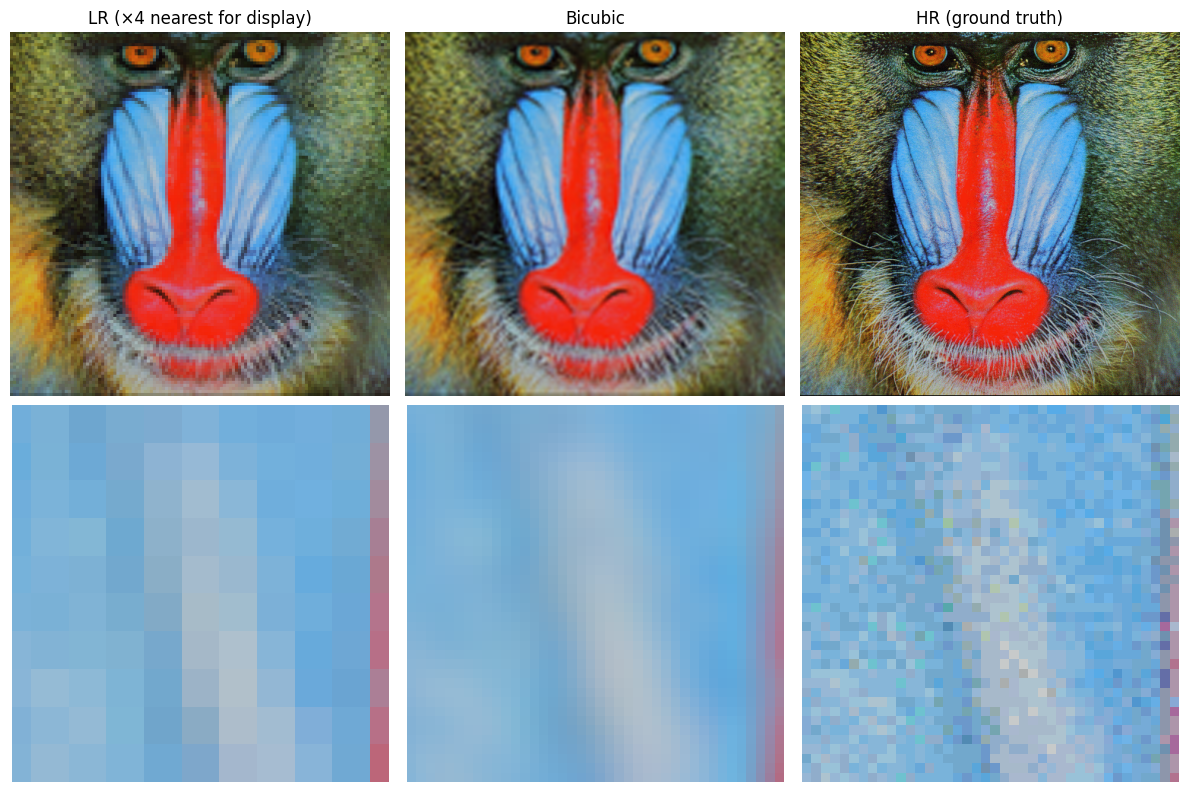

In [13]:
import matplotlib.pyplot as plt, numpy as np
from src.eval.evaluate import to_np

ds = datasets["Set14"]; lr, hr = ds[0]
sr = Bicubic(4)(lr[None])[0]
h, w = hr.shape[1:]; y, x, s = h // 3, w // 3, 40        # crop zone
crops = {"LR (×4 nearest for display)": torch.nn.functional.interpolate(lr[None], scale_factor=4, mode="nearest")[0],
         "Bicubic": sr, "HR (ground truth)": hr}
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for j, (t, im) in enumerate(crops.items()):
    ax[0, j].imshow(to_np(im)); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].imshow(to_np(im)[y:y+s, x:x+s], interpolation="nearest"); ax[1, j].axis("off")
Path("results/figures").mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig("results/figures/bicubic_zoom_example.png", dpi=150); plt.show()

In [14]:
!zip -r colab_outputs.zip data/splits data/raw results/tables results/figures
from google.colab import files
files.download("colab_outputs.zip")

  adding: data/splits/ (stored 0%)
  adding: data/splits/train.txt (deflated 77%)
  adding: data/splits/test.txt (deflated 71%)
  adding: data/splits/val.txt (deflated 71%)
  adding: data/raw/ (stored 0%)
  adding: data/raw/DIV2K_train_HR/ (stored 0%)
  adding: data/raw/DIV2K_train_HR/0744.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0545.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0560.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0192.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0538.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0194.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0577.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0087.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0478.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0305.png (deflated 1%)
  adding: data/raw/DIV2K_train_HR/0520.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0725.png (deflated 0%)
  adding: data/raw/DIV2K_train_HR/0231.png (deflated 0%)
  addin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
!zip -r colab_outputs2.zip data/splits  results/tables results/figures
from google.colab import files
files.download("colab_outputs2.zip")

  adding: data/splits/ (stored 0%)
  adding: data/splits/train.txt (deflated 77%)
  adding: data/splits/test.txt (deflated 71%)
  adding: data/splits/val.txt (deflated 71%)
  adding: results/tables/ (stored 0%)
  adding: results/tables/per_image_bicubic.csv (deflated 59%)
  adding: results/tables/speed_bicubic.csv (deflated 38%)
  adding: results/tables/summary_bicubic.csv (deflated 22%)
  adding: results/figures/ (stored 0%)
  adding: results/figures/bicubic_zoom_example.png (deflated 1%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>